# 07 – Final model for people without a known diabetes diagnosis

Same steps as notebook 06, but people who reported a diabetes diagnosis are removed, because the tool is meant for screening people who do not know their status (advice from my instructor).

This notebook contains the **final model**, the **final test** and the **saved model** used by the website (notebook 08).

## 7.1 Load the 10-feature dataset

In [1]:
import pandas as pd
df=pd.read_csv('../data/processed/nhanes_model_ready.csv')
df

,age_years,is_female,bmi,waist_cm,hip_cm,waist_to_height,waist_to_hip,race_ethnicity_code,education_code,income_poverty_ratio,elevated_hbA1c
0,43,0,27.0,98.3,102.9,0.547632,0.955296,Asian,College graduate,5.00,0
1,66,0,33.5,114.7,112.4,0.658439,1.020463,White,College graduate,5.00,0
2,44,1,29.7,93.5,98.0,0.611511,0.954082,Other Hispanic,High school,1.41,1
3,34,0,30.2,106.1,110.6,0.612233,0.959313,Mexican American,Some college,1.33,0
4,68,1,42.6,122.0,148.9,0.782553,0.819342,White,College graduate,1.32,1
...,...,...,...,...,...,...,...,...,...,...,...
5762,69,1,27.9,111.0,104.5,0.697236,1.062201,Other or Multiracial,High school,0.98,1
5763,76,1,26.4,89.0,96.4,0.587847,0.923237,Mexican American,Less than 9th grade,2.25,1
5764,49,1,NaN,NaN,NaN,NaN,NaN,Black,College graduate,NaN,1
5765,40,0,25.5,96.0,103.3,0.536013,0.929332,Other Hispanic,Some college,3.11,0


In [2]:
df.shape

(5767, 11)

## 7.2 Load the blood pressure and cholesterol questions

In [3]:

import pandas as pd
from pathlib import Path

data_dir = Path("../data")

BPQ = pd.read_sas(data_dir / "BPQ_L.xpt", format="xport")

print(BPQ.shape)
BPQ.head()

(8501, 6)


,SEQN,BPQ020,BPQ030,BPQ150,BPQ080,BPQ101D
0,130378.0,1.0,1.0,1.0,2.0,2.0
1,130379.0,1.0,1.0,1.0,2.0,2.0
2,130380.0,2.0,NaN,NaN,1.0,1.0
3,130384.0,2.0,NaN,NaN,2.0,2.0
4,130385.0,2.0,NaN,NaN,2.0,2.0


## 7.3 Keep the columns we need

In [4]:
BPQ = BPQ[['SEQN', 'BPQ020', 'BPQ080', 'BPQ150', 'BPQ101D']]
print(BPQ.shape)

(8501, 5)


In [5]:
BPQ.isna().sum()

SEQN          0
BPQ020        3
BPQ080        3
BPQ150     5532
BPQ101D       3
dtype: int64

## 7.4 Attach SEQN: safety check

In [6]:
clean = pd.read_csv('../data/processed/nhanes_clean.csv')
print(df['bmi'].equals(clean['bmi']))

True


## 7.5 Merge the blood pressure and cholesterol questions

In [7]:
df['SEQN'] = clean['SEQN']
df = df.merge(BPQ, on='SEQN', how='left')
print(df.shape)

(5767, 16)


In [8]:
df.head()

,age_years,is_female,bmi,waist_cm,hip_cm,waist_to_height,waist_to_hip,race_ethnicity_code,education_code,income_poverty_ratio,elevated_hbA1c,SEQN,BPQ020,BPQ080,BPQ150,BPQ101D
0,43,0,27.0,98.3,102.9,0.547632,0.955296,Asian,College graduate,5.00,0,130378,1.0,2.0,1.0,2.0
1,66,0,33.5,114.7,112.4,0.658439,1.020463,White,College graduate,5.00,0,130379,1.0,2.0,1.0,2.0
2,44,1,29.7,93.5,98.0,0.611511,0.954082,Other Hispanic,High school,1.41,1,130380,2.0,1.0,NaN,1.0
3,34,0,30.2,106.1,110.6,0.612233,0.959313,Mexican American,Some college,1.33,0,130386,2.0,2.0,NaN,2.0
4,68,1,42.6,122.0,148.9,0.782553,0.819342,White,College graduate,1.32,1,130387,1.0,1.0,1.0,2.0


In [9]:
df['BPQ020'].value_counts()

BPQ020
2.0    3567
1.0    2196
9.0       4
Name: count, dtype: int64

## 7.6 Recode the answers to 0/1

In [10]:
df['bp_told'] = df['BPQ020'].map({1: 1, 2: 0})
df['chol_told'] = df['BPQ080'].map({1: 1, 2: 0})
df['chol_med'] = df['BPQ101D'].map({1: 1, 2: 0})
df['bp_med'] = df['BPQ150'].map({1: 1, 2: 0})
df.loc[df['BPQ020'] == 2, 'bp_med'] = 0


In [11]:
new_cols = ['bp_told', 'chol_told', 'bp_med', 'chol_med']
print(df[new_cols].isna().sum())
print(df[new_cols].sum())

bp_told       4
chol_told    34
bp_med        7
chol_med     26
dtype: int64
bp_told      2196.0
chol_told    2400.0
bp_med       1827.0
chol_med     1659.0
dtype: float64


## 7.7 Load the diabetes questionnaire

In [12]:
diq= pd.read_csv('../data/processed/diq_prepared.csv')

print(diq.shape)
print(diq.columns)
diq.head()

(7809, 3)
Index(['SEQN', 'diabetes_reported', 'prediabetes_reported'], dtype='str')


,SEQN,diabetes_reported,prediabetes_reported
0,130378.0,2.0,2.0
1,130379.0,2.0,2.0
2,130380.0,1.0,NaN
3,130384.0,2.0,2.0
4,130385.0,2.0,1.0


## 7.8 Remove people with a known diabetes diagnosis

**Note:** People who answered "yes, a doctor told me I have diabetes" (code 1) are removed. Everyone else stays.

In [13]:
# 1. Bring the diagnosis answer into df (like the BPQ merge)

df = df.merge(diq[['SEQN', 'diabetes_reported']], on='SEQN', how='left')

print(df.shape)

# 2. keep only people who did not answer 'yes' (1)

df=df[df['diabetes_reported'] !=1]

print(df.shape)

(5767, 21)
(4948, 21)


## 7.9 Drop helper columns, make X and y

In [14]:
df = df.drop(columns=['SEQN', 'BPQ020', 'BPQ080', 'BPQ150', 'BPQ101D', 'diabetes_reported', 'income_poverty_ratio'])
y = df.pop('elevated_hbA1c')
X = df
print(X.shape)

(4948, 13)


## 7.10 Split, preprocessor and model (cross-validation)

In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score, roc_auc_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

num_features = X_train.select_dtypes(include='number').columns.tolist()
print(num_features)

num_pipe = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
ord_pipe = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OrdinalEncoder(categories=[['Less than 9th grade', '9th to 11th grade',
                                'High school', 'Some college', 'College graduate']]))
nom_pipe = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore', sparse_output=False))

preprocessor = make_column_transformer(
    (num_pipe, num_features),
    (ord_pipe, ['education_code']),
    (nom_pipe, ['race_ethnicity_code']))

model_c = make_pipeline(preprocessor, LogisticRegression(max_iter=1000))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(model_c, X_train, y_train, cv=cv, scoring=['roc_auc', 'recall'])
print('ROC-AUC:', scores['test_roc_auc'].mean().round(3))
print('Recall :', scores['test_recall'].mean().round(3))

['age_years', 'is_female', 'bmi', 'waist_cm', 'hip_cm', 'waist_to_height', 'waist_to_hip', 'bp_told', 'chol_told', 'chol_med', 'bp_med']
ROC-AUC: 0.766
Recall : 0.387


## 7.11 Comparison: all people (notebook 06) vs people without a diabetes diagnosis (notebook 07)
Logistic regression, cross-validated ROC-AUC. Notebook 06: 14 features (with income). Notebook 07: 13 features (without income).

| | Notebook 06: all people | Notebook 07: undiagnosed only |
|---|---|---|
| People | 5,767 | 4,948 |
| Training people (elevated) | 4,613 (1,839) | 3,958 (1,236) |
| ROC-AUC | 0.800 | 0.766 |
| Recall at threshold 0.5 | 0.607 | 0.387 |

**Note:** The 819 removed people were mostly easy cases (high HbA1c, clear risk factors). The lower score reflects the real screening task.

## 7.12 Threshold table (cross-validated)

In [16]:
from sklearn.model_selection import cross_val_predict

proba = cross_val_predict(model_c, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

for t in [0.5, 0.4, 0.3, 0.25, 0.2]:
    pred = (proba >= t).astype(int)
    print('Threshold', t)
    print(confusion_matrix(y_train, pred))
    print('Recall:', round(recall_score(y_train, pred), 3),
          ' Precision:', round(precision_score(y_train, pred), 3))
    print()

Threshold 0.5
[[2389  333]
 [ 757  479]]
Recall: 0.388  Precision: 0.59

Threshold 0.4
[[2137  585]
 [ 528  708]]
Recall: 0.573  Precision: 0.548

Threshold 0.3
[[1786  936]
 [ 330  906]]
Recall: 0.733  Precision: 0.492

Threshold 0.25
[[1578 1144]
 [ 232 1004]]
Recall: 0.812  Precision: 0.467

Threshold 0.2
[[1312 1410]
 [ 139 1097]]
Recall: 0.888  Precision: 0.438



## 7.13 Threshold results (cross-validated, 3,958 training people: 1,236 elevated, 2,722 not)

| Threshold | Elevated people found (recall) | Healthy people wrongly flagged | Flagged who are truly elevated (precision) |
|---|---|---|---|
| 0.5 | 39% | 12% | 59% |
| 0.4 | 57% | 21% | 55% |
| 0.3 | 73% | 34% | 49% |
| 0.25 | 81% | 42% | 47% |
| 0.2 | 89% | 52% | 44% |

**Reading the table:** a lower threshold finds more elevated people, but also flags more healthy people.
At the default of 0.5, the model misses 61% of elevated people, which is too many for a screening tool.

## 7.14 Which features can the app ask for?

| Features | Cross-validated ROC-AUC |
|---|---|
| All 14 (including income) | 0.766 |
| 13, without income (**final model**) | 0.766 |
| 12, without income and race | 0.751 |

**Decision:** income is removed (no loss, and users cannot answer it). Race and education stay; the app offers "Prefer not to say", which the pipeline fills with the most common answer.

**Note:** This check was run with 5-fold cross-validation on the training data, before income was removed.

## 7.15 Threshold choice: 0.2

Chosen on the cross-validated training results (7.13), before the final test.
At 0.2 the model finds 89% of people with elevated HbA1c, with 52% false alarms.
For a screening tool, a missed case is worse than an extra blood test (instructor's advice: fewest false negatives).

## 7.16 Final test: logistic regression, 13 features, threshold 0.2

**Note:** The test set is used once, here.

In [17]:
final_model = model_c.fit(X_train, y_train)

THRESHOLD = 0.2
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= THRESHOLD).astype(int)

print('ROC-AUC  :', round(roc_auc_score(y_test, test_proba), 3))
print('Recall   :', round(recall_score(y_test, test_pred), 3))
print('Precision:', round(precision_score(y_test, test_pred), 3))
print('Accuracy :', round(accuracy_score(y_test, test_pred), 3))
print(confusion_matrix(y_test, test_pred))

ROC-AUC  : 0.761
Recall   : 0.89
Precision: 0.436
Accuracy : 0.606
[[325 356]
 [ 34 275]]


## 7.17 Final result (test set, 990 people: 309 elevated, 681 not)

| Measure | Value | In words |
|---|---|---|
| ROC-AUC | 0.761 | ranks people well; matches cross-validation (0.766) |
| Recall | 0.89 | finds 275 of 309 elevated people, misses 34 |
| False alarms | 52% | 356 of 681 people without elevated HbA1c are flagged |
| Precision | 0.44 | 44 of every 100 flagged people are truly elevated |
| Accuracy | 0.61 | low on purpose: the threshold favours finding cases over being right overall |

**Conclusion:** the model behaves on new people as expected from training, with no sign of overfitting. As a screening tool it finds about 9 of 10 people with elevated HbA1c, at the cost of many follow-up blood tests.

## 7.18 Save the final model

**Note:** The website will load this file. It contains the whole pipeline: the imputers, the scaler, the encoders and the logistic regression.

In [18]:
import joblib
from pathlib import Path

model_dir = Path('../models')
model_dir.mkdir(exist_ok=True)

joblib.dump(final_model, model_dir / 'hba1c_risk_model.joblib')
print('Model saved')

Model saved


## 7.19 Check the saved model with one example person

In [19]:
import numpy as np

loaded_model = joblib.load(model_dir / 'hba1c_risk_model.joblib')

person = pd.DataFrame([{
    'age_years': 55, 'is_female': 1, 'bmi': 29.4,
    'waist_cm': 98, 'hip_cm': 108,
    'waist_to_height': 98 / 165, 'waist_to_hip': 98 / 108,
    'race_ethnicity_code': np.nan,          # "Prefer not to say"
    'education_code': 'High school',
    'bp_told': 1, 'chol_told': 0, 'chol_med': 0, 'bp_med': 1,
}])

risk = loaded_model.predict_proba(person)[0, 1]
print('Risk:', round(risk * 100), '%')
print('Elevated risk' if risk >= 0.2 else 'Low risk')

Risk: 24 %
Elevated risk


## 7.20 Pictures for the presentation: confusion matrix and ROC curve (final test)

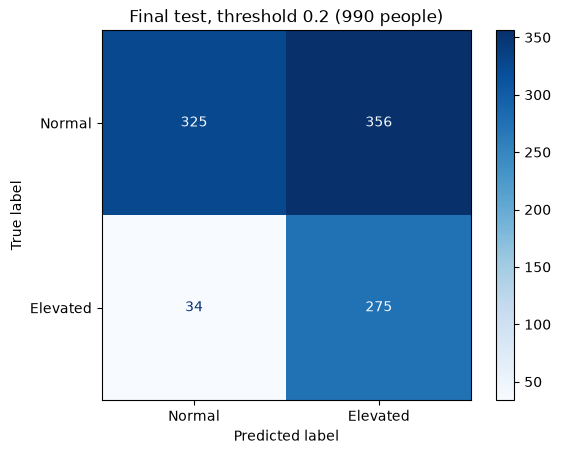

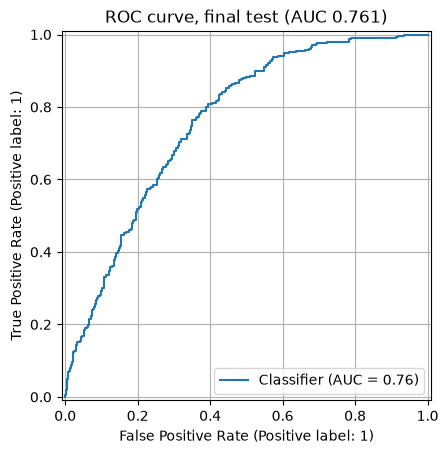

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# Picture 1: the four boxes (rows = truth, columns = prediction)
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred,
    display_labels=["Normal", "Elevated"],
    cmap="Blues"
)
plt.title("Final test, threshold 0.2 (990 people)")
plt.show()

# Picture 2: the ROC curve (uses the probabilities, not the yes/no answers)
RocCurveDisplay.from_predictions(y_test, test_proba)
plt.title("ROC curve, final test (AUC 0.761)")
plt.grid(True)
plt.show()